In [148]:
import pandas as pd
df = pd.read_csv("../data/train.csv")
print(df.shape)

(891, 12)


In [149]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

# 한글 폰트 (Windows)
sns.set_style("whitegrid")
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
RANDOM_STATE = 42

In [150]:
df = pd.read_csv("../data/train.csv")
print("데이터 shape:", df.shape)   # (891, 12)
df.head()

데이터 shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [151]:
df.info()
df.describe()
df.describe(include="object")

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


## 1. 데이터셋 소개
- 데이터: Kaggle Titanic - Machine Learning from Disaster (train.csv)
- 목적: 승객 정보를 이용해 생존 여부 예측 (이진 분류)
- 타겟 변수: Survived (0 = 사망, 1 = 생존)
- 샘플 수 891개 (500개 이상 조건 충족), 수치형 + 범주형 변수 혼합

Cabin       77.10
Age         19.87
Embarked     0.22
dtype: float64


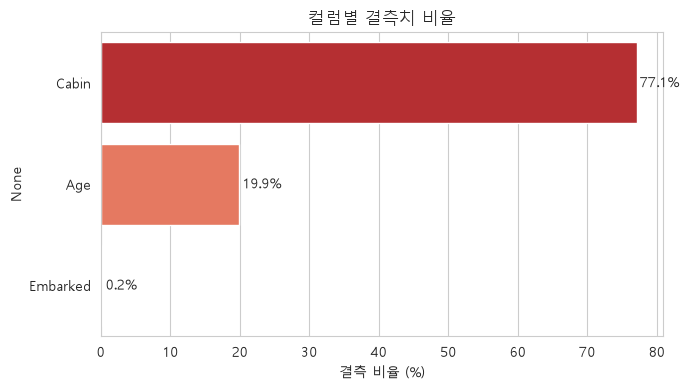

In [152]:
missing = (df.isnull().mean() * 100).sort_values(ascending=False)
missing = missing[missing > 0]
print(missing.round(2))

plt.figure(figsize=(7, 4))
sns.barplot(x=missing.values, y=missing.index, palette="Reds_r")
plt.xlabel("결측 비율 (%)")
plt.title("컬럼별 결측치 비율")
for i, v in enumerate(missing.values):
    plt.text(v + 0.5, i, f"{v:.1f}%", va="center")
plt.tight_layout()
plt.savefig("../figures/01_missing.png", dpi=150)
plt.show()

Survived
0    549
1    342
Name: count, dtype: int64
Survived
0    0.616
1    0.384
Name: proportion, dtype: float64


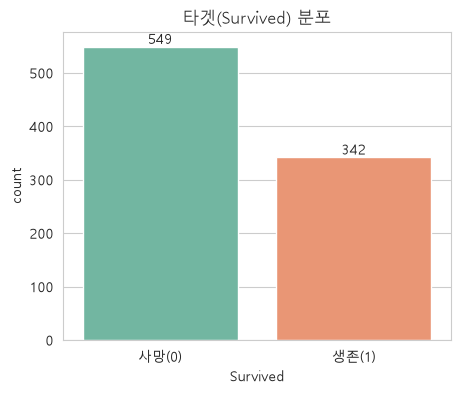

In [153]:
print(df["Survived"].value_counts())
print(df["Survived"].value_counts(normalize=True).round(3))

plt.figure(figsize=(5, 4))
ax = sns.countplot(x="Survived", data=df, palette="Set2")
ax.set_xticklabels(["사망(0)", "생존(1)"])
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom")
plt.title("타겟(Survived) 분포")
plt.savefig("../figures/02_target.png", dpi=150)
plt.show()

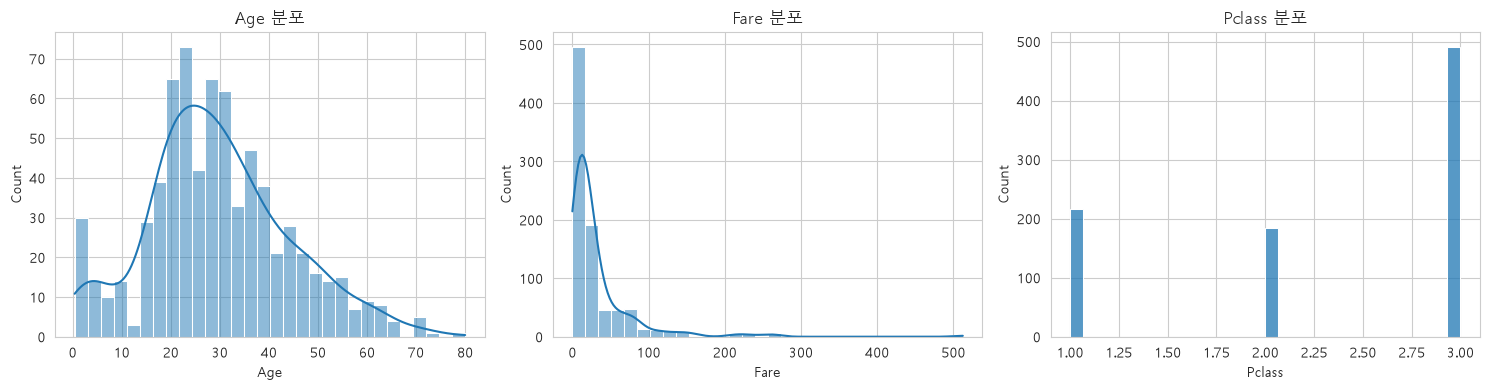

Fare 왜도: 4.79


In [154]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Age", "Fare", "Pclass"]):
    sns.histplot(df[col].dropna(), bins=30, kde=(col != "Pclass"), ax=ax)
    ax.set_title(f"{col} 분포")
plt.tight_layout()
plt.savefig("../figures/03_hist.png", dpi=150)
plt.show()

print("Fare 왜도:", round(df["Fare"].skew(), 2))

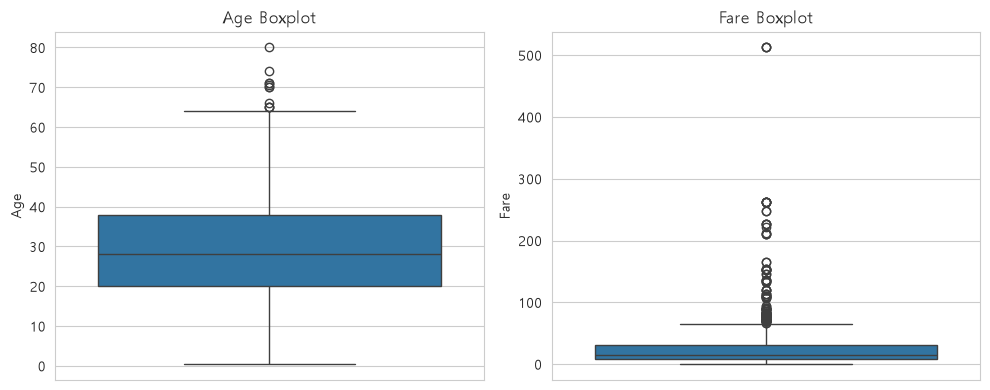

Age: 이상치 11개 (정상 범위 -6.69 ~ 64.81)
Fare: 이상치 116개 (정상 범위 -26.72 ~ 65.63)


In [155]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(y=df["Age"], ax=axes[0]); axes[0].set_title("Age Boxplot")
sns.boxplot(y=df["Fare"], ax=axes[1]); axes[1].set_title("Fare Boxplot")
plt.tight_layout()
plt.savefig("../figures/04_boxplot.png", dpi=150)
plt.show()

def iqr_outliers(s):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5*iqr, q3 + 1.5*iqr
    return ((s < low) | (s > high)).sum(), round(low, 2), round(high, 2)

for col in ["Age", "Fare"]:
    n, low, high = iqr_outliers(df[col])
    print(f"{col}: 이상치 {n}개 (정상 범위 {low} ~ {high})")

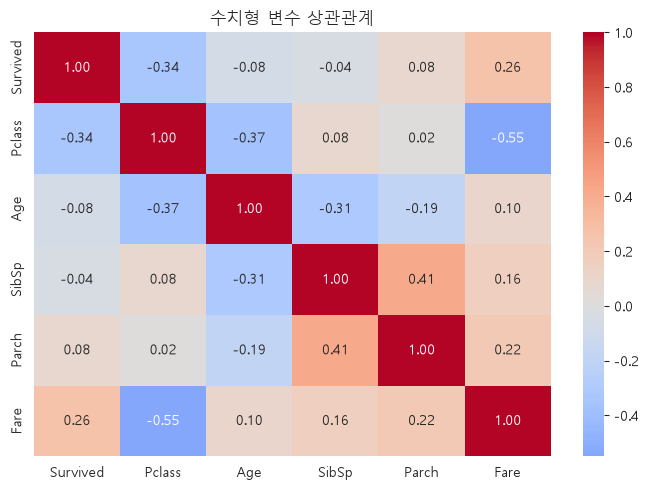

In [156]:
num_df = df.drop(columns=["PassengerId"]).select_dtypes("number")
plt.figure(figsize=(7, 5))
sns.heatmap(num_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("수치형 변수 상관관계")
plt.tight_layout()
plt.savefig("../figures/05_heatmap.png", dpi=150)
plt.show()

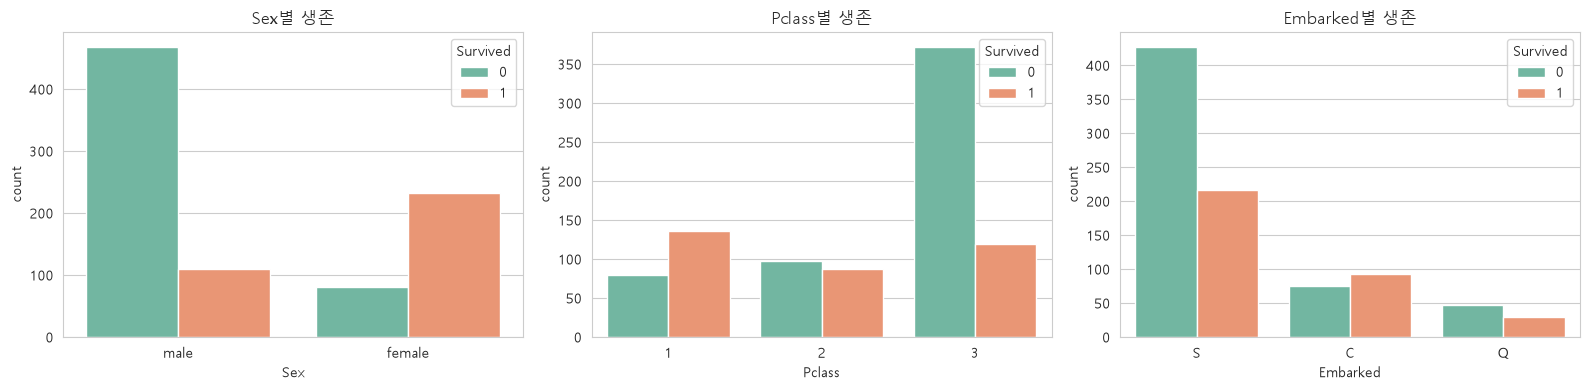

Sex
female    0.742
male      0.189
Name: Survived, dtype: float64 

Pclass
1    0.630
2    0.473
3    0.242
Name: Survived, dtype: float64 

Embarked
C    0.554
Q    0.390
S    0.337
Name: Survived, dtype: float64 



In [157]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["Sex", "Pclass", "Embarked"]):
    sns.countplot(x=col, hue="Survived", data=df, ax=ax, palette="Set2")
    ax.set_title(f"{col}별 생존")
plt.tight_layout()
plt.savefig("../figures/06_cat_vs_target.png", dpi=150)
plt.show()

# 생존율 수치
for col in ["Sex", "Pclass", "Embarked"]:
    print(df.groupby(col)["Survived"].mean().round(3), "\n")

## EDA 요약

### 1) 데이터 품질 문제
- Cabin 결측 약 77% → 원본 사용 불가, HasCabin 파생변수로 활용
- Age 결측 약 20% → 대체 방법 비교 필요
- Embarked 결측 2개 → 최빈값 대체
- Fare 이상치 다수 (IQR 기준 116개) → RobustScaler 비교 근거

### 2) 불균형 여부
- 사망 61.6% / 생존 38.4% → 약한 불균형, Accuracy 외에 F1, AUC도 함께 평가

### 3) 주요 변수 특징
- 여성 생존율 74.2% vs 남성 18.9%
- 1등석 생존율 63.0% vs 3등석 24.2%
- Fare는 오른쪽으로 치우친 분포 (왜도 4.79)

## 3. 특성 공학 (Feature Engineering)

### 3-1. 파생변수 생성

| 파생변수 | 생성 방법 | 생성 이유 |
|---|---|---|
| Title | Name에서 호칭 추출 (Mr, Mrs, Miss, Master, Rare) | 성별·나이·신분 정보를 함께 담음 |
| FamilySize | SibSp + Parch + 1 | 가족 규모가 생존에 영향을 줄 것으로 판단 |
| IsAlone | FamilySize == 1 | 혼자 탑승 여부 |
| FarePerPerson | Fare / FamilySize | 단체 구매 요금의 왜곡 보정 |
| HasCabin | Cabin 결측 여부 | 결측 77%인 Cabin을 정보로 활용 |
| AgeGroup | Age를 5개 구간으로 분할 | 연령대별 생존 패턴 반영 |

※ Name, Ticket, PassengerId, Cabin 원본은 모델 입력에서 제외

In [158]:
df_fe = df.copy()

# 1) Title: 이름에서 호칭 추출
df_fe["Title"] = df_fe["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
df_fe["Title"] = df_fe["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
rare = df_fe["Title"].value_counts()[lambda s: s < 10].index
df_fe["Title"] = df_fe["Title"].replace(rare, "Rare")

# 2) FamilySize, IsAlone
df_fe["FamilySize"] = df_fe["SibSp"] + df_fe["Parch"] + 1
df_fe["IsAlone"] = (df_fe["FamilySize"] == 1).astype(int)

# 3) FarePerPerson
df_fe["FarePerPerson"] = df_fe["Fare"] / df_fe["FamilySize"]

# 4) HasCabin
df_fe["HasCabin"] = df_fe["Cabin"].notnull().astype(int)

# 5) AgeGroup (Age 결측은 NaN으로 유지 → 이후 imputer 단계에서 처리)
df_fe["AgeGroup"] = pd.cut(df_fe["Age"], bins=[0, 12, 18, 35, 60, 100],
                           labels=["Child", "Teen", "Adult", "Middle", "Senior"])
df_fe["AgeGroup"] = df_fe["AgeGroup"].astype(object)   # 결측 처리 호환용

print(df_fe["Title"].value_counts())
df_fe[["Name", "Title", "FamilySize", "IsAlone", "FarePerPerson", "HasCabin", "AgeGroup"]].head(10)

Title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64


,Name,Title,FamilySize,IsAlone,FarePerPerson,HasCabin,AgeGroup
0,"Braund, Mr. Owen Harris",Mr,2,0,3.62500,0,Adult
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,2,0,35.64165,1,Middle
2,"Heikkinen, Miss. Laina",Miss,1,1,7.92500,0,Adult
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,2,0,26.55000,1,Adult
4,"Allen, Mr. William Henry",Mr,1,1,8.05000,0,Adult
5,"Moran, Mr. James",Mr,1,1,8.45830,0,NaN
6,"McCarthy, Mr. Timothy J",Mr,1,1,51.86250,1,Middle
7,"Palsson, Master. Gosta Leonard",Master,5,0,4.21500,0,Child
8,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",Mrs,3,0,3.71110,0,Adult
9,"Nasser, Mrs. Nicholas (Adele Achem)",Mrs,2,0,15.03540,0,Teen


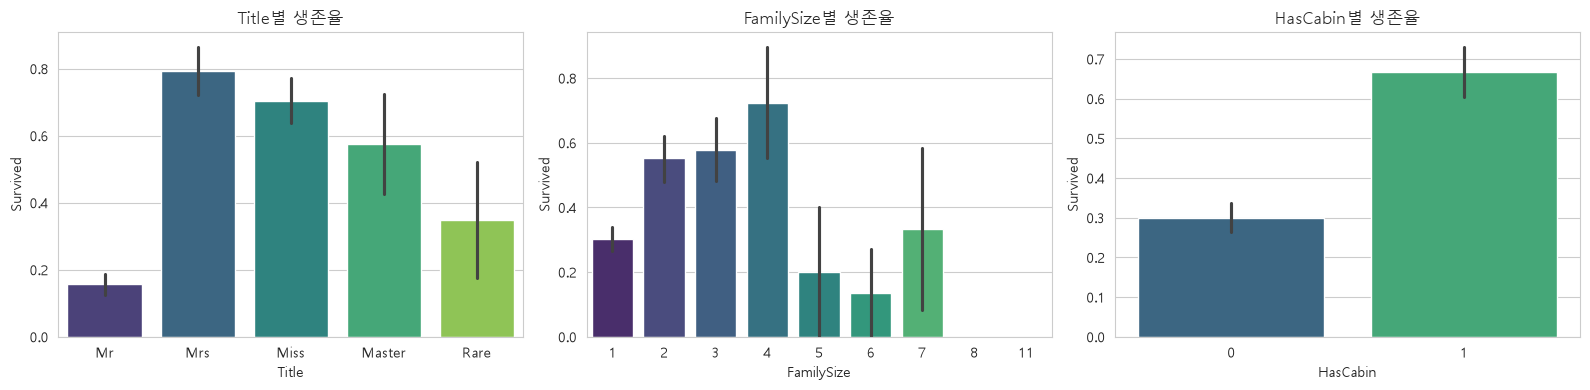

In [159]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["Title", "FamilySize", "HasCabin"]):
    sns.barplot(x=col, y="Survived", data=df_fe, ax=ax, palette="viridis")
    ax.set_title(f"{col}별 생존율")
plt.tight_layout()
plt.savefig("../figures/07_derived.png", dpi=150)
plt.show()

**해석**
- Title: Mrs/Miss는 생존율이 높고 Mr는 낮음 → 성별+신분 정보를 효과적으로 반영
- FamilySize: 4인 가족에서 생존율이 가장 높고, 혼자(1) 또는 대가족(5 이상)은 낮음
- HasCabin: Cabin 정보가 있는 승객의 생존율이 30% vs 없는 승객 66%

In [160]:
y = df_fe["Survived"]

# 원본 컬럼 vs 파생변수 포함 컬럼 (FE 기여도 비교용)
base_num = ["Age", "Fare", "SibSp", "Parch", "Pclass"]
base_cat = ["Sex", "Embarked"]

fe_num = base_num + ["FamilySize", "IsAlone", "FarePerPerson", "HasCabin"]
fe_cat = base_cat + ["Title", "AgeGroup"]

X_orig = df_fe[base_num + base_cat]          # 파생변수 없음
X_fe   = df_fe[fe_num + fe_cat]              # 파생변수 포함

print("원본 특성:", X_orig.shape, " / 파생 포함:", X_fe.shape)

원본 특성: (891, 7)  / 파생 포함: (891, 13)


In [161]:
from sklearn.model_selection import train_test_split

idx_train, idx_test = train_test_split(
    df_fe.index, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

y_train, y_test = y.loc[idx_train], y.loc[idx_test]
print("train:", len(idx_train), " / test:", len(idx_test))
print("생존율 train/test:", y_train.mean().round(3), y_test.mean().round(3))

train: 712  / test: 179
생존율 train/test: 0.383 0.385


### 3-2. 전처리 파이프라인 설계

- sklearn `Pipeline` + `ColumnTransformer`로 **결측치 처리 → 인코딩 → 스케일링 → (변수 선택) → 모델**을 하나의 객체로 구성
- **데이터 누수 방지**: 대체값·평균·인코더는 train fold에서만 fit, validation/test에는 transform만 적용 (CV 내부에서도 동일)
- 평가: train/test 8:2 분할(stratify) 후, train 내부에서 Stratified 5-Fold CV로 비교, test는 최종 확인용
- Label Encoding은 특성용 `OrdinalEncoder`로 구현
- 범주형 결측치는 모든 실험에서 최빈값으로 통일 (비교 대상은 수치형 처리 방식)

| 실험 | 결측치(수치형) | 인코딩 | 스케일링 | Feature Selection |
|---|---|---|---|---|
| Base | 없음 | 없음 | 없음 | 없음 |
| Exp-1 | Mean | One-Hot | Standard | X |
| Exp-2 | Median | Label(Ordinal) | MinMax | O (K=8) |
| Exp-3 | Most Frequent | One-Hot | Robust | O (K=8) |

In [162]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, RobustScaler,
                                   OneHotEncoder, OrdinalEncoder)
from sklearn.feature_selection import SelectKBest, f_classif

def get_scaler(name):
    return {"standard": StandardScaler(), "minmax": MinMaxScaler(),
            "robust": RobustScaler(), "none": "passthrough"}[name]

def get_encoder(name):
    if name == "onehot":
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    return OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)

def build_preprocessor(num_cols, cat_cols, num_strategy, encoder, scaler):
    num_pipe = Pipeline([
        ("imp", SimpleImputer(strategy=num_strategy)),
        ("scale", get_scaler(scaler)),
    ])
    cat_pipe = Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("enc", get_encoder(encoder)),
    ])
    return ColumnTransformer([("num", num_pipe, num_cols),
                              ("cat", cat_pipe, cat_cols)])

# 과제 표 그대로
EXPERIMENTS = {
    "Exp-1": dict(num_strategy="mean",          encoder="onehot",  scaler="standard", select=False),
    "Exp-2": dict(num_strategy="median",        encoder="ordinal", scaler="minmax",   select=True),
    "Exp-3": dict(num_strategy="most_frequent", encoder="onehot",  scaler="robust",   select=True),
}
K_SELECT = 8   # 일단 8로 두고, STEP 04에서 최적 N을 찾아 바꿀 예정

In [163]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

MODELS = {
    "LR":  LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "RF":  RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    "XGB": XGBClassifier(n_estimators=200, eval_metric="logloss",
                         random_state=RANDOM_STATE, verbosity=0),
    "LGBM": LGBMClassifier(n_estimators=200, random_state=RANDOM_STATE, verbose=-1),
}

SCORING = ["accuracy", "precision", "recall", "f1", "roc_auc"]
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def evaluate(pipe, X, label_exp, label_model, extra=None):
    """CV(train 데이터 안에서) + 최종 test 성능을 한 줄 dict로 반환"""
    X_tr, X_te = X.loc[idx_train], X.loc[idx_test]

    cv_res = cross_validate(pipe, X_tr, y_train, cv=CV, scoring=SCORING,
                            return_train_score=True, n_jobs=-1)
    pipe.fit(X_tr, y_train)
    pred = pipe.predict(X_te)
    proba = pipe.predict_proba(X_te)[:, 1]

    from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                                 f1_score, roc_auc_score)
    row = {
        "실험": label_exp, "모델": label_model,
        "CV_Acc": cv_res["test_accuracy"].mean(),
        "CV_Acc_std": cv_res["test_accuracy"].std(),
        "CV_F1": cv_res["test_f1"].mean(),
        "CV_AUC": cv_res["test_roc_auc"].mean(),
        "Train_Acc": cv_res["train_accuracy"].mean(),
        "Gap": cv_res["train_accuracy"].mean() - cv_res["test_accuracy"].mean(),
        "Test_Acc": accuracy_score(y_test, pred),
        "Test_Prec": precision_score(y_test, pred),
        "Test_Rec": recall_score(y_test, pred),
        "Test_F1": f1_score(y_test, pred),
        "Test_AUC": roc_auc_score(y_test, proba),
    }
    if extra: row.update(extra)
    return row

### 3-3. 실험 결과

**Base**: 결측이 없는 수치형 4개(Pclass, SibSp, Parch, Fare)만 사용하며 범주형과 Age는 제외. 전처리 없음.

In [164]:
from sklearn.base import clone

results = []

# Base: 결측 없는 수치형만, 변환 없음 (Age 제외)
base_cols = ["Pclass", "SibSp", "Parch", "Fare"]
X_base = df_fe[base_cols]

for mname, model in MODELS.items():
    pipe = Pipeline([("model", clone(model))])
    results.append(evaluate(pipe, X_base, "Base", mname))

pd.DataFrame(results)[["실험", "모델", "CV_Acc", "CV_F1", "CV_AUC", "Gap", "Test_Acc"]].round(4)

,실험,모델,CV_Acc,CV_F1,CV_AUC,Gap,Test_Acc
0,Base,LR,0.6952,0.5333,0.7060,0.0014,0.6480
1,Base,RF,0.7247,0.6091,0.7501,0.1373,0.5922
2,Base,XGB,0.7289,0.6128,0.7611,0.1289,0.6257
3,Base,LGBM,0.7219,0.5949,0.7745,0.1043,0.6536


In [165]:
def run_experiment(exp_name, cfg, X, num_cols, cat_cols, tag=""):
    rows = []
    for mname, model in MODELS.items():
        steps = [("prep", build_preprocessor(num_cols, cat_cols,
                                             cfg["num_strategy"], cfg["encoder"], cfg["scaler"]))]
        if cfg["select"]:
            steps.append(("select", SelectKBest(f_classif, k=K_SELECT)))
        steps.append(("model", clone(model)))
        pipe = Pipeline(steps)
        rows.append(evaluate(pipe, X, exp_name + tag, mname))
    return rows

# 파생변수 포함 버전으로 Exp-1~3 실행
for exp_name, cfg in EXPERIMENTS.items():
    results += run_experiment(exp_name, cfg, X_fe, fe_num, fe_cat)

res_df = pd.DataFrame(results)
res_df.round(4)

,실험,모델,CV_Acc,CV_Acc_std,CV_F1,CV_AUC,Train_Acc,Gap,Test_Acc,Test_Prec,Test_Rec,Test_F1,Test_AUC
0,Base,LR,0.6952,0.0143,0.5333,0.7060,0.6966,0.0014,0.6480,0.5625,0.3913,0.4615,0.6742
1,Base,RF,0.7247,0.0260,0.6091,0.7501,0.8620,0.1373,0.5922,0.4714,0.4783,0.4748,0.6450
2,Base,XGB,0.7289,0.0225,0.6128,0.7611,0.8578,0.1289,0.6257,0.5172,0.4348,0.4724,0.6312
3,Base,LGBM,0.7219,0.0139,0.5949,0.7745,0.8262,0.1043,0.6536,0.5556,0.5072,0.5303,0.6385
4,Exp-1,LR,0.8244,0.0288,0.7705,0.8691,0.8339,0.0095,0.8324,0.8000,0.7536,0.7761,0.8756
5,Exp-1,RF,0.8175,0.0246,0.7524,0.8743,0.9888,0.1713,0.7877,0.7183,0.7391,0.7286,0.8264
6,Exp-1,XGB,0.8132,0.0253,0.7469,0.8813,0.9881,0.1749,0.8156,0.7647,0.7536,0.7591,0.8364
7,Exp-1,LGBM,0.8174,0.0271,0.7533,0.8824,0.9856,0.1682,0.8156,0.7647,0.7536,0.7591,0.8263
8,Exp-2,LR,0.7894,0.0267,0.7287,0.8512,0.7960,0.0066,0.7654,0.6957,0.6957,0.6957,0.8260
9,Exp-2,RF,0.8105,0.0268,0.7494,0.8608,0.9582,0.1477,0.7765,0.7377,0.6522,0.6923,0.8007


In [166]:
cols = ["실험", "모델", "CV_Acc", "CV_Acc_std", "CV_F1", "CV_AUC", "Gap",
        "Test_Acc", "Test_Prec", "Test_Rec", "Test_F1", "Test_AUC"]
table = res_df[cols].round(4)
table.to_csv("../results/experiment_results.csv", index=False, encoding="utf-8-sig")

# 모델별 한눈에 보기
print(table.pivot(index="실험", columns="모델", values="CV_Acc").round(4))

모델       LGBM      LR      RF     XGB
실험                                   
Base   0.7219  0.6952  0.7247  0.7289
Exp-1  0.8174  0.8244  0.8175  0.8132
Exp-2  0.8118  0.7894  0.8105  0.8062
Exp-3  0.8231  0.7922  0.8006  0.8245


**결과 해석**
- Base 대비 Exp-1~3 모두 CV Accuracy가 약 6~13%p 상승 (Exp-1 기준 LR +12.9%p, LGBM +9.6%p, RF +9.3%p, XGB +8.4%p) → 범주형(Sex, Title)과 파생변수 활용의 효과가 큼
- 최고 성능 조합: Accuracy 기준으로는 Exp-1(LR) 0.8244와 Exp-3(XGB) 0.8245가 사실상 동률. AUC 기준으로는 Exp-1(LGBM) 0.8824, Exp-1(XGB) 0.8813이 가장 높음. 종합하면 **Exp-1(Mean + One-Hot + Standard, FS 없음)** 이 AUC 최고이고 Accuracy도 최상위권
- 모델 간 차이: Base에서는 LR(Acc 0.695, AUC 0.706)이 트리 모델(Acc 0.72~0.73, AUC 0.75~0.77)보다 낮았으나, 전처리 후에는 LR이 Exp-1에서 Acc 최고 수준(0.8244)으로 올라섬 → 범주형 인코딩과 스케일링이 선형 모델에 특히 큰 도움이 됨. 트리 모델은 Base에서도 비교적 높아 상승폭이 작음
- 표준편차(Exp-1~3 기준 약 0.008~0.030, 대부분 0.02 안팎) 대비 Exp 간 차이가 작아 **유의미한 차이로 보기 어려운 구간**도 있음 (예: Exp-1의 LGBM/RF/XGB는 0.813~0.818로 거의 동일, Exp-1 LR 0.8244와 Exp-3 XGB 0.8245의 차이는 표준편차의 1/100 수준). 반면 Base와 Exp-1~3의 차이(6~13%p)는 표준편차의 3배 이상이라 유의미함
- Feature Selection(Exp-2, 3)은 Gap이 Exp-1 대비 감소 (LGBM 0.168 → 0.139 / 0.089, RF 0.171 → 0.148 / 0.134, XGB 0.175 → 0.152 / 0.106) → 트리 계열 모델의 과적합이 완화됨. 다만 CV AUC는 Exp-1(0.874~0.882)보다 Exp-2, 3(0.851~0.874)이 낮아 **정확도·AUC 이득 없이 Gap만 줄어든 결과**임. LR은 Gap이 0.01 미만으로 원래 과적합이 거의 없음
- 한계: Exp-1과 Exp-2/3은 결측 처리·인코딩·스케일링도 함께 달라 FS만의 순수 효과로 단정할 수 없음 → STEP 04에서 동일 전처리 기준으로 FS on/off를 다시 비교

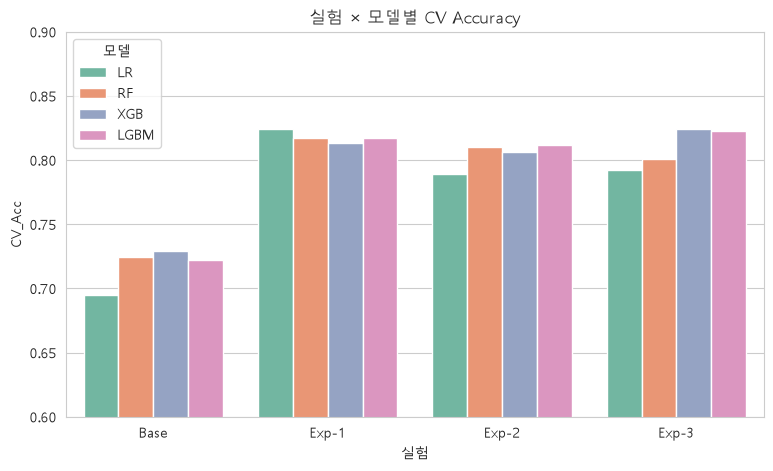

In [167]:
plt.figure(figsize=(9, 5))
sns.barplot(x="실험", y="CV_Acc", hue="모델", data=res_df, palette="Set2")
plt.ylim(0.6, 0.9)
plt.title("실험 × 모델별 CV Accuracy")
plt.savefig("../figures/08_experiment_compare.png", dpi=150)
plt.show()

In [168]:
extra = []
fixed = dict(num_strategy="median", select=False)

# Q1: One-Hot vs Ordinal (스케일링 고정)
for enc in ["onehot", "ordinal"]:
    cfg = {**fixed, "encoder": enc, "scaler": "standard"}
    extra += run_experiment(f"Enc:{enc}", cfg, X_fe, fe_num, fe_cat)

# Q2: 스케일링 영향 (인코딩 고정)
for sc in ["none", "standard", "minmax", "robust"]:
    cfg = {**fixed, "encoder": "onehot", "scaler": sc}
    extra += run_experiment(f"Scale:{sc}", cfg, X_fe, fe_num, fe_cat)

# Q3: 파생변수 없음 vs 있음 (전처리 고정)
cfg = {**fixed, "encoder": "onehot", "scaler": "standard"}
extra += run_experiment("FE:없음", cfg, X_orig, base_num, base_cat)
extra += run_experiment("FE:있음", cfg, X_fe, fe_num, fe_cat)

extra_df = pd.DataFrame(extra)
extra_df.round(4).to_csv("../results/extra_experiments.csv", index=False, encoding="utf-8-sig")

for key in ["Enc", "Scale", "FE"]:
    sub = extra_df[extra_df["실험"].str.startswith(key)]
    print(f"\n=== {key} 비교 (CV_Acc / CV_AUC) ===")
    print(sub.pivot(index="실험", columns="모델", values="CV_Acc").round(4))
    print(sub.pivot(index="실험", columns="모델", values="CV_AUC").round(4))


=== Enc 비교 (CV_Acc / CV_AUC) ===
모델             LGBM      LR      RF     XGB
실험                                         
Enc:onehot   0.8146  0.8230  0.8217  0.8076
Enc:ordinal  0.8132  0.7992  0.8175  0.8062
모델             LGBM      LR      RF     XGB
실험                                         
Enc:onehot   0.8811  0.8687  0.8755  0.8831
Enc:ordinal  0.8782  0.8587  0.8780  0.8792

=== Scale 비교 (CV_Acc / CV_AUC) ===
모델                LGBM      LR      RF     XGB
실험                                            
Scale:minmax    0.8132  0.8202  0.8203  0.8076
Scale:none      0.8132  0.8230  0.8203  0.8076
Scale:robust    0.8203  0.8216  0.8189  0.8062
Scale:standard  0.8146  0.8230  0.8217  0.8076
모델                LGBM      LR      RF     XGB
실험                                            
Scale:minmax    0.8808  0.8726  0.8745  0.8831
Scale:none      0.8808  0.8682  0.8752  0.8831
Scale:robust    0.8805  0.8686  0.8742  0.8839
Scale:standard  0.8811  0.8687  0.8755  0.8831

=== FE 비교 (CV

### 3-4. 추가 비교 실험 (통제 실험)

한 번에 한 요소만 바꾸고 나머지는 고정(결측 median, FS 없음)하여 영향을 분리함.

**① One-Hot vs Ordinal**
- LR: OHE Acc 0.8230 vs Ordinal 0.7992 → OHE가 2.4%p 높음, AUC도 0.8687 vs 0.8587로 1.0%p 높음. Ordinal은 Sex, Embarked, Title 같은 명목형 변수에 가짜 순서를 부여해 선형 모델에 불리하게 작용한 것으로 해석됨
- LGBM/RF/XGB: Acc 차이 0.14~0.42%p, AUC 차이 -0.25~+0.39%p로 사실상 동일 (표준편차 약 0.02 대비 매우 작음) → 트리 모델은 인코딩 방식에 둔감하며 Ordinal로도 충분함
- 결론: **One-Hot이 항상 좋은 것은 아님.** 선형 모델(LR)에는 유의미하게 유리했지만, 트리 모델에서는 차이가 없었고 오히려 RF AUC는 Ordinal이 근소하게 높았음. 단, LR의 2.4%p 차이도 표준편차(약 0.02~0.03)와 비슷한 수준이라 확정적 우위라기보다 경향으로 해석함

**② 스케일링 영향**
- LR: none 0.8230 / standard 0.8230 / minmax 0.8202 / robust 0.8216 → 최대 차이 0.28%p로 거의 없음. AUC도 0.8682~0.8726으로 동일 수준
- LGBM 0.8132~0.8203, RF 0.8189~0.8217, XGB 0.8062~0.8076 → 최대 차이 0.7%p 이내로 거의 동일 (트리는 분할 기준이 순서 기반이라 스케일에 불변이며, 미세한 차이는 변동 수준)
- 예상과 달리 LR에서도 스케일링 효과가 거의 없었음. 이는 LR이 기본 L2 정규화와 lbfgs 솔버로 수렴했고, 수치형 변수가 Age, Fare, FarePerPerson 등 소수이며 One-Hot 변수가 다수라 스케일 차이의 영향이 제한적이었기 때문으로 추측됨
- 결론: 이 데이터셋에서는 **스케일링이 모델 성능에 큰 영향을 주지 않았음** (LR, 트리 모두 0.8%p 이내)

**③ 파생변수 기여도**
- CV Accuracy 기준: LGBM 0.8132→0.8146 (+0.1%p), LR 0.7963→0.8230 (+2.7%p), RF 0.8020→0.8217 (+2.0%p), XGB 0.7907→0.8076 (+1.7%p) → 평균 +1.6%p, 4개 모델 모두 상승
- CV AUC 기준: LGBM 0.8710→0.8811 (+1.0%p), LR 0.8551→0.8687 (+1.4%p), RF 0.8633→0.8755 (+1.2%p), XGB 0.8668→0.8831 (+1.6%p) → 평균 +1.3%p, 4개 모델 모두 상승
- 해석: 파생변수(Title, FamilySize, HasCabin 등)가 4개 모델 모두에서 Accuracy와 AUC를 같은 방향으로 개선함. 특히 LR(+2.7%p)과 RF(+2.0%p)에서 효과가 컸고, LGBM은 Accuracy 상승폭이 0.1%p로 사실상 변화가 없음. 다만 상승폭은 CV 표준편차(약 0.02~0.03)와 비슷하거나 작은 수준이라, "큰 폭의 개선"이 아니라 **"일관된 방향의 소폭 개선"** 으로 해석함. 원본 변수(Sex, Pclass 등)만으로도 이미 높은 성능을 내기 때문으로 보임

## 4. 변수 선택 (Feature Selection)

### 4-1. 변수 선택 방법
- 전처리(Mean 대체 + One-Hot + StandardScaler) 후 특성은 총 24개
- **Random Forest Feature Importance**로 상위 N개를 선정하고, 막대그래프에서 상위 10개를 빨간색으로 강조하여 시각화
- **Permutation Importance**(test 데이터, AUC 기준)로 RF 불순도 중요도의 편향 여부를 교차 확인
- **SelectKBest(f_classif)** 로 통계량 기반 점수를 계산하고 RF 결과와 비교
- 실제 모델 적용에는 SelectKBest를 사용하며, 누수 방지를 위해 **Pipeline 내부에서 train fold로만 fit**
- 변수 선택 전/후 성능은 전처리를 동일하게 고정하고 FS만 on/off 하여 비교

In [169]:
from sklearn.ensemble import RandomForestClassifier

# 기준 전처리: Exp-1 설정 (Mean + OneHot + Standard), train 데이터로만 fit
prep = build_preprocessor(fe_num, fe_cat, "mean", "onehot", "standard")
X_tr_fe = X_fe.loc[idx_train]
X_te_fe = X_fe.loc[idx_test]

Xt_train = prep.fit_transform(X_tr_fe)
feature_names = prep.get_feature_names_out()
feature_names = [n.split("__", 1)[1] for n in feature_names]   # num__Age -> Age

print("전처리 후 특성 수:", len(feature_names))
print(feature_names)

전처리 후 특성 수: 24
['Age', 'Fare', 'SibSp', 'Parch', 'Pclass', 'FamilySize', 'IsAlone', 'FarePerPerson', 'HasCabin', 'Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S', 'Title_Master', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare', 'AgeGroup_Adult', 'AgeGroup_Child', 'AgeGroup_Middle', 'AgeGroup_Senior', 'AgeGroup_Teen']


Age               0.1534
FarePerPerson     0.1426
Fare              0.1352
Sex_male          0.0915
Sex_female        0.0838
Title_Mr          0.0807
Pclass            0.0510
FamilySize        0.0392
HasCabin          0.0384
Title_Mrs         0.0256
Title_Miss        0.0248
SibSp             0.0244
Parch             0.0166
Embarked_S        0.0159
AgeGroup_Adult    0.0118
dtype: float64


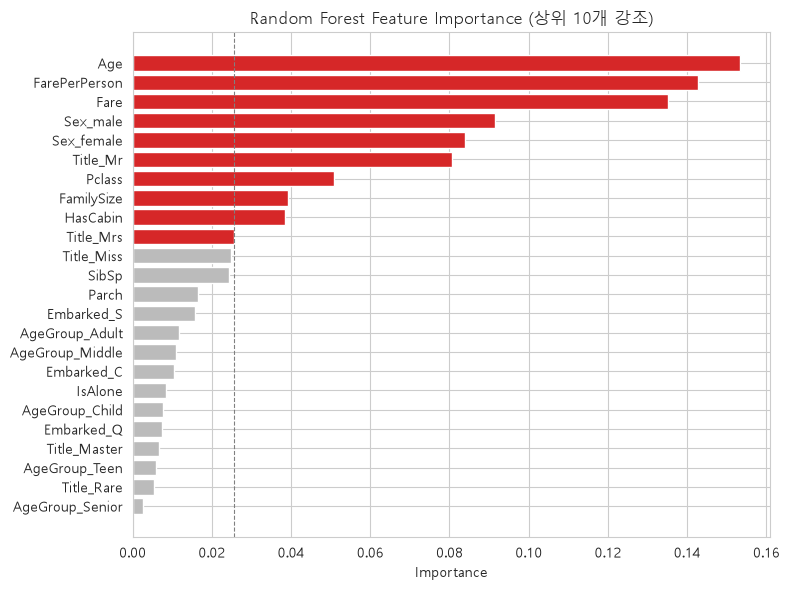

In [170]:
rf = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE)
rf.fit(Xt_train, y_train)

imp = pd.Series(rf.feature_importances_, index=feature_names).sort_values(ascending=False)
print(imp.head(15).round(4))

TOP_N = 10
plt.figure(figsize=(8, 6))
colors = ["#d62728" if i < TOP_N else "#bbbbbb" for i in range(len(imp))]
plt.barh(imp.index[::-1], imp.values[::-1], color=colors[::-1])
plt.axvline(imp.values[TOP_N-1], color="gray", linestyle="--", linewidth=0.8)
plt.xlabel("Importance")
plt.title(f"Random Forest Feature Importance (상위 {TOP_N}개 강조)")
plt.tight_layout()
plt.savefig("../figures/09_rf_importance.png", dpi=150)
plt.show()

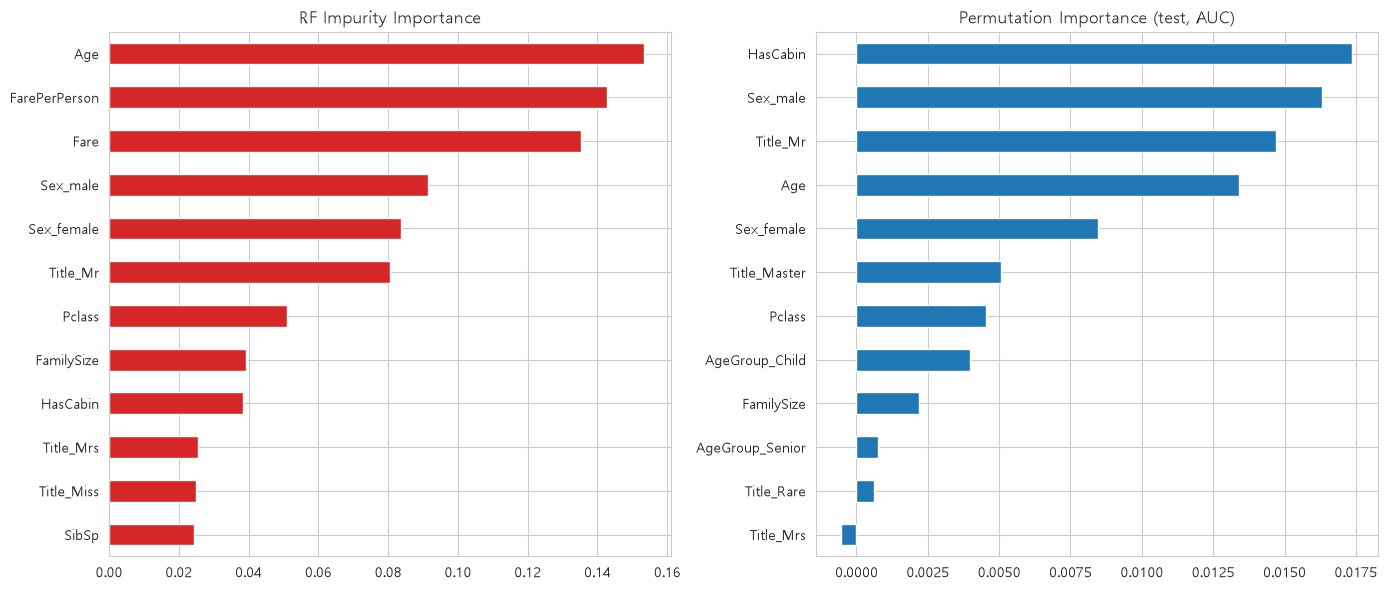

In [171]:
from sklearn.inspection import permutation_importance

Xt_test = prep.transform(X_te_fe)
perm = permutation_importance(rf, Xt_test, y_test, n_repeats=20,
                              random_state=RANDOM_STATE, scoring="roc_auc")
perm_s = pd.Series(perm.importances_mean, index=feature_names).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
imp.head(12)[::-1].plot.barh(ax=axes[0], color="#d62728"); axes[0].set_title("RF Impurity Importance")
perm_s.head(12)[::-1].plot.barh(ax=axes[1], color="#1f77b4"); axes[1].set_title("Permutation Importance (test, AUC)")
plt.tight_layout()
plt.savefig("../figures/10_importance_compare.png", dpi=150)
plt.show()

In [172]:
skb = SelectKBest(f_classif, k="all").fit(Xt_train, y_train)
skb_s = pd.Series(skb.scores_, index=feature_names).sort_values(ascending=False)

print(skb_s.head(12).round(2))

# RF 상위 10 vs SelectKBest 상위 10 비교
print("\n공통 변수:", set(imp.head(10).index) & set(skb_s.head(10).index))
print("RF에만:", set(imp.head(10).index) - set(skb_s.head(10).index))
print("SelectKBest에만:", set(skb_s.head(10).index) - set(imp.head(10).index))

Title_Mr         317.02
Sex_female       306.59
Sex_male         306.59
HasCabin          99.46
Pclass            97.84
Title_Mrs         97.43
Title_Miss        90.64
Fare              58.31
FarePerPerson     36.80
IsAlone           34.60
Embarked_C        23.78
Embarked_S        23.55
dtype: float64

공통 변수: {'FarePerPerson', 'Pclass', 'Title_Mrs', 'Sex_male', 'Title_Mr', 'Fare', 'HasCabin', 'Sex_female'}
RF에만: {'FamilySize', 'Age'}
SelectKBest에만: {'Title_Miss', 'IsAlone'}


### 4-2. 중요도 결과 해석
- RF 상위 변수: Age(0.153), FarePerPerson(0.143), Fare(0.135), Sex_male(0.092), Sex_female(0.084), Title_Mr(0.081)
- 상위 10개 중 파생변수가 5개(FarePerPerson, Title_Mr, FamilySize, HasCabin, Title_Mrs) 포함 → 파생변수가 모델에서 실제로 활용됨
- Sex_male과 Sex_female은 동일 변수의 OHE 결과로, 합산 중요도는 0.175로 가장 높음
- RF 불순도 중요도는 값의 종류가 많은 연속형(Age, Fare, FarePerPerson)이 상위 3위인데, 연속형에 유리한 편향 때문으로 해석됨
- Permutation Importance(test AUC)에서는 HasCabin, Sex_male, Title_Mr, Age, Sex_female이 상위 → 파생변수(HasCabin, Title_Mr)가 오히려 상위권이며, Fare/FarePerPerson은 순위가 크게 떨어짐. 두 변수가 서로 상관이 높아 하나를 섞어도 다른 쪽이 정보를 보완하기 때문으로 추측됨
- RF와 SelectKBest 상위 10개의 공통 변수는 8개(FarePerPerson, Pclass, Title_Mrs, Sex_male, Title_Mr, Fare, HasCabin, Sex_female). RF에만 FamilySize·Age, SelectKBest에만 Title_Miss·IsAlone가 포함됨. 선형 통계량 기반인 SelectKBest는 Age 같은 비선형 효과를 놓치는 경향이 있음
- 세 방식 모두 **성별(Sex, Title), HasCabin, Pclass**를 핵심으로 꼽아 결과가 대체로 일관됨
- 하위권(Title_Rare, AgeGroup_Senior 등)은 RF 중요도 0.01 미만. 단, Title_Master는 Permutation에서 상위권이라 방법에 따라 평가가 다름

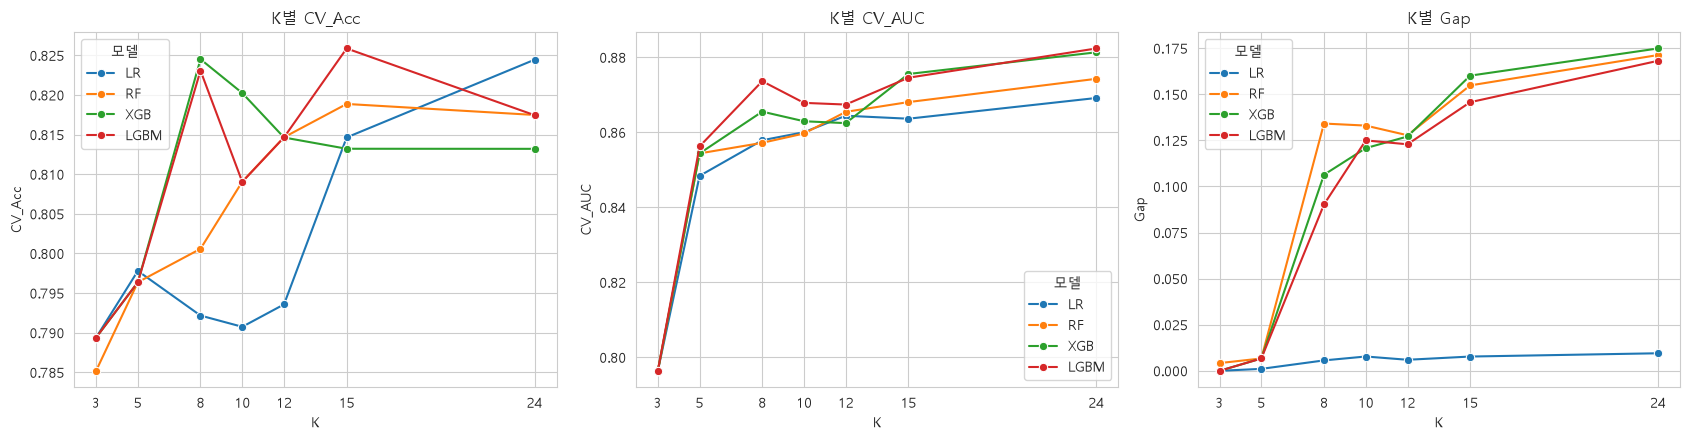

모델    LGBM      LR      RF     XGB
K                                 
3   0.7894  0.7894  0.7852  0.7894
5   0.7964  0.7978  0.7964  0.7964
8   0.8231  0.7922  0.8006  0.8245
10  0.8090  0.7907  0.8091  0.8202
12  0.8146  0.7936  0.8147  0.8146
15  0.8259  0.8146  0.8189  0.8132
24  0.8174  0.8244  0.8175  0.8132
모델    LGBM      LR      RF     XGB
K                                 
3   0.7964  0.7964  0.7964  0.7964
5   0.8562  0.8484  0.8544  0.8544
8   0.8736  0.8579  0.8572  0.8655
10  0.8678  0.8600  0.8597  0.8629
12  0.8674  0.8644  0.8654  0.8624
15  0.8745  0.8636  0.8680  0.8755
24  0.8824  0.8691  0.8743  0.8813
모델    LGBM      LR      RF     XGB
K                                 
3  -0.0001 -0.0001  0.0041 -0.0001
5   0.0067  0.0010  0.0067  0.0067
8   0.0902  0.0056  0.1341  0.1063
10  0.1250  0.0077  0.1330  0.1208
12  0.1229  0.0059  0.1278  0.1271
15  0.1457  0.0077  0.1548  0.1601
24  0.1682  0.0095  0.1713  0.1749


In [173]:
X_tr_fe = X_fe.loc[idx_train]
n_total = len(feature_names)
k_list = [3, 5, 8, 10, 12, 15, n_total]
k_list = sorted(set(k for k in k_list if k <= n_total))

curve = []
for name in ["LR", "RF", "XGB", "LGBM"]:
    for k in k_list:
        pipe = Pipeline([
            ("prep", build_preprocessor(fe_num, fe_cat, "mean", "onehot", "standard")),
            ("select", SelectKBest(f_classif, k=k)),
            ("model", clone(MODELS[name])),
        ])
        cv = cross_validate(pipe, X_tr_fe, y_train, cv=CV,
                            scoring=["accuracy", "roc_auc"],
                            return_train_score=True, n_jobs=-1)
        curve.append({
            "모델": name, "K": k,
            "CV_Acc": cv["test_accuracy"].mean(),
            "CV_AUC": cv["test_roc_auc"].mean(),
            "Gap": cv["train_accuracy"].mean() - cv["test_accuracy"].mean(),
        })

curve_df = pd.DataFrame(curve)
curve_df.round(4).to_csv("../results/k_curve.csv", index=False, encoding="utf-8-sig")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, metric in zip(axes, ["CV_Acc", "CV_AUC", "Gap"]):
    sns.lineplot(data=curve_df, x="K", y=metric, hue="모델", marker="o", ax=ax)
    ax.set_title(f"K별 {metric}")
    ax.set_xticks(k_list)
plt.tight_layout()
plt.savefig("../figures/11_k_curve.png", dpi=150)
plt.show()

print(curve_df.pivot(index="K", columns="모델", values="CV_Acc").round(4))
print(curve_df.pivot(index="K", columns="모델", values="CV_AUC").round(4))
print(curve_df.pivot(index="K", columns="모델", values="Gap").round(4))

### 4-3. 최적 N 선정
- K를 3~24(전체)로 바꿔가며 Pipeline 내부에서 CV 평가 (누수 방지)
- K=3은 AUC 0.796으로 급락, K=5는 0.848~0.856으로 개선되나 아직 정보 손실이 큼
- **K=8에서 AUC가 0.857~0.874로 올라 엘보우를 형성**하고, 이후 K=10~15는 완만하게 증가하여 전체(K=24, 0.869~0.882) 대비 차이가 0.7~1.2%p 수준
- Gap은 K=8에서 트리 모델이 0.090~0.134로 전체(0.168~0.175) 대비 감소, LR은 전 구간 0.01 미만
- 전체 대비 성능 손실이 약간 있으나 과적합이 줄고 특성 수가 1/3로 감소하므로 **BEST_K = 8** 선택
- 한계: 전체 특성이 성능 최고이므로, 이 데이터에서 FS는 "성능 향상"이 아니라 "모델 단순화·과적합 완화" 목적임


In [174]:
BEST_K = 8

rows = []
for name in ["LR", "RF", "XGB", "LGBM"]:
    for label, use_fs in [("FS 전(전체)", False), ("FS 후(상위 K)", True)]:
        steps = [("prep", build_preprocessor(fe_num, fe_cat, "mean", "onehot", "standard"))]
        if use_fs:
            steps.append(("select", SelectKBest(f_classif, k=BEST_K)))
        steps.append(("model", clone(MODELS[name])))
        pipe = Pipeline(steps)
        r = evaluate(pipe, X_fe, label, name)
        rows.append(r)

fs_df = pd.DataFrame(rows)
fs_cols = ["실험", "모델", "CV_Acc", "CV_Acc_std", "CV_F1", "CV_AUC", "Gap",
           "Test_Acc", "Test_F1", "Test_AUC"]
fs_df[fs_cols].round(4).to_csv("../results/fs_before_after.csv", index=False, encoding="utf-8-sig")
fs_df[fs_cols].round(4)

,실험,모델,CV_Acc,CV_Acc_std,CV_F1,CV_AUC,Gap,Test_Acc,Test_F1,Test_AUC
0,FS 전(전체),LR,0.8244,0.0288,0.7705,0.8691,0.0095,0.8324,0.7761,0.8756
1,FS 후(상위 K),LR,0.7922,0.0178,0.7270,0.8579,0.0056,0.7709,0.6963,0.8208
2,FS 전(전체),RF,0.8175,0.0246,0.7524,0.8743,0.1713,0.7877,0.7286,0.8264
3,FS 후(상위 K),RF,0.8006,0.0189,0.7388,0.8572,0.1341,0.7598,0.6906,0.7917
4,FS 전(전체),XGB,0.8132,0.0253,0.7469,0.8813,0.1749,0.8156,0.7591,0.8364
5,FS 후(상위 K),XGB,0.8245,0.0300,0.7650,0.8655,0.1063,0.7598,0.6861,0.8090
6,FS 전(전체),LGBM,0.8174,0.0271,0.7533,0.8824,0.1682,0.8156,0.7591,0.8263
7,FS 후(상위 K),LGBM,0.8231,0.0159,0.7631,0.8736,0.0902,0.7821,0.7153,0.8034


### 4-4. FS 전/후 비교 (전처리 동일: Mean + One-Hot + Standard, K=8)
- Gap: LR 0.0095→0.0056, RF 0.1713→0.1341, XGB 0.1749→0.1063, LGBM 0.1682→0.0902 → 트리 모델에서 과적합 격차가 뚜렷이 감소(약 22~46%)
- CV AUC: 4개 모델 모두 0.9~1.7%p 하락 (LR 0.869→0.858, RF 0.874→0.857, XGB 0.881→0.866, LGBM 0.882→0.874)
- CV Accuracy: XGB(+1.1%p), LGBM(+0.6%p)는 소폭 상승했으나 표준편차(0.016~0.030) 이내라 유의미하지 않고, LR(−3.2%p)과 RF(−1.7%p)는 하락
- Test AUC: 4개 모델 모두 2.3~5.5%p 하락 (LR 0.876→0.821, RF 0.826→0.792, XGB 0.836→0.809, LGBM 0.826→0.803)
- 결론: Feature Selection은 **트리 모델의 과적합(Gap)을 줄였지만 AUC는 일관되게 하락**했다. "과적합 완화"는 사실이나 "일반화 성능 향상"으로는 이어지지 않음. 제거된 16개 특성에도 일부 유효 정보가 있었던 것으로 해석됨
- 한계: Test는 179개 샘플이라 변동이 크며, K=8은 선형 통계량(f_classif) 기준이라 RF 중요도 상위였던 Age가 제외됨

In [175]:
# 변화량 한눈에 보기
for metric in ["CV_Acc", "CV_AUC", "Gap", "Test_AUC"]:
    p = fs_df.pivot(index="모델", columns="실험", values=metric)
    p["변화(후-전)"] = p["FS 후(상위 K)"] - p["FS 전(전체)"]
    print(f"\n=== {metric} ===")
    print(p.round(4))


=== CV_Acc ===
실험    FS 전(전체)  FS 후(상위 K)  변화(후-전)
모델                                 
LGBM    0.8174      0.8231   0.0056
LR      0.8244      0.7922  -0.0323
RF      0.8175      0.8006  -0.0169
XGB     0.8132      0.8245   0.0113

=== CV_AUC ===
실험    FS 전(전체)  FS 후(상위 K)  변화(후-전)
모델                                 
LGBM    0.8824      0.8736  -0.0087
LR      0.8691      0.8579  -0.0113
RF      0.8743      0.8572  -0.0171
XGB     0.8813      0.8655  -0.0158

=== Gap ===
실험    FS 전(전체)  FS 후(상위 K)  변화(후-전)
모델                                 
LGBM    0.1682      0.0902  -0.0779
LR      0.0095      0.0056  -0.0039
RF      0.1713      0.1341  -0.0372
XGB     0.1749      0.1063  -0.0685

=== Test_AUC ===
실험    FS 전(전체)  FS 후(상위 K)  변화(후-전)
모델                                 
LGBM    0.8263      0.8034  -0.0229
LR      0.8756      0.8208  -0.0549
RF      0.8264      0.7917  -0.0347
XGB     0.8364      0.8090  -0.0275
